In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path
df = pd.read_csv(Path("data") / "spotify_data.csv")

In [3]:
df

,track_name,artists,track_genre,danceability,energy,valence,tempo,acousticness,liveness,instrumentalness,loudness,speechiness
0,Blinding Lights,The Weeknd,pop,0.514,0.730,0.334,171.005,0.00146,0.0897,0.000095,-5.934,0.0598
1,Save Your Tears,The Weeknd,pop,0.680,0.826,0.644,118.091,0.02120,0.5430,0.000011,-5.187,0.0300
2,Shape of You,Ed Sheeran,pop,0.825,0.652,0.931,95.977,0.58100,0.0931,0.000011,-3.183,0.0802
3,Perfect,Ed Sheeran,pop,0.599,0.448,0.168,95.050,0.16300,0.1060,0.000000,-6.312,0.0232
4,Someone You Loved,Lewis Capaldi,pop,0.501,0.405,0.446,109.891,0.75100,0.1050,0.000000,-5.679,0.0319
5,Stay,The Kid LAROI,pop,0.591,0.764,0.478,169.928,0.03830,0.1030,0.000000,-5.484,0.0485
6,Levitating,Dua Lipa,pop,0.702,0.825,0.915,103.012,0.05610,0.0674,0.000001,-3.787,0.0755
7,As It Was,Harry Styles,pop,0.520,0.731,0.662,173.930,0.34200,0.3110,0.001010,-5.338,0.0557
8,Bad Guy,Billie Eilish,pop,0.701,0.425,0.562,135.128,0.32800,0.1000,0.130000,-10.965,0.3750
9,Believer,Imagine Dragons,rock,0.776,0.780,0.666,124.949,0.06220,0.0810,0.000000,-4.374,0.1110


C:\Users\Jaine\AppData\Local\Temp\ipykernel_21128\3841831752.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_artists.values, y=top_artists.index, palette="viridis")


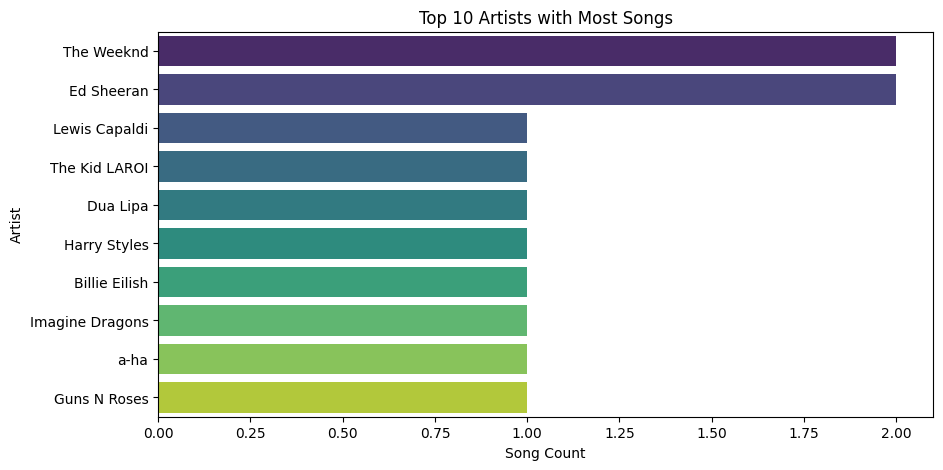

In [4]:

top_artists = df['artists'].value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top_artists.values, y=top_artists.index, palette="viridis")
plt.title("Top 10 Artists with Most Songs")
plt.xlabel("Song Count")
plt.ylabel("Artist")
plt.show()


C:\Users\Jaine\AppData\Local\Temp\ipykernel_21128\1650816481.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, palette="magma")


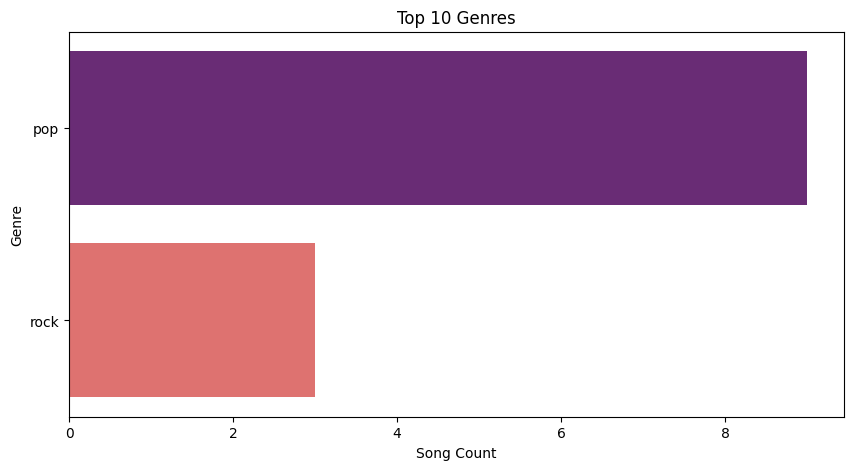

In [5]:
top_genres = df['track_genre'].value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top_genres.values, y=top_genres.index, palette="magma")
plt.title("Top 10 Genres")
plt.xlabel("Song Count")
plt.ylabel("Genre")
plt.show()

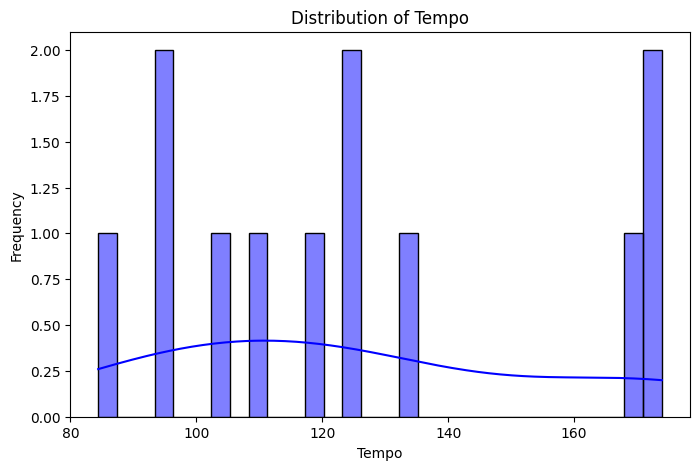

In [6]:
plt.figure(figsize=(8,5))
sns.histplot(df['tempo'], bins=30, kde=True, color="blue")
plt.title("Distribution of Tempo")
plt.xlabel("Tempo")
plt.ylabel("Frequency")
plt.show()

In [7]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

feature_cols = [c for c in ["danceability","energy","valence","tempo","acousticness",
                            "liveness","instrumentalness","loudness","speechiness"]
                if c in df.columns]
X = df[feature_cols].values

# Fit kNN on features
knn = NearestNeighbors(n_neighbors=11, metric="cosine")  # 1 is the song itself + 10 neighbors
knn.fit(X)

def find_track_index(query_track, query_artist=None):
    q = query_track.strip().lower()
    if query_artist:
        mask = (df["track_name"].str.lower()==q) & (df["artists"].str.lower()==query_artist.strip().lower())
    else:
        mask = (df["track_name"].str.lower()==q)
    matches = df[mask]
    if matches.empty:
        # fallback: contains (simple)
        matches = df[df["track_name"].str.lower().str.contains(q)]
    return matches.index[0] if not matches.empty else None

def recommend_content_based(track_name, artist_name=None, k=5):
    idx = find_track_index(track_name, artist_name)
    if idx is None:
        return []
    distances, indices = knn.kneighbors(X[idx].reshape(1,-1), n_neighbors=k+1)
    # skip self (first result)
    rec_idx = [i for i in indices.flatten() if i!=idx][:k]
    return df.iloc[rec_idx][["track_name","artists"]].to_dict(orient="records")


In [8]:
recommend_content_based("Blinding Lights", "The Weeknd", k=5)

[{'track_name': 'Stay', 'artists': 'The Kid LAROI'},
 {'track_name': 'As It Was', 'artists': 'Harry Styles'},
 {'track_name': 'Believer', 'artists': 'Imagine Dragons'},
 {'track_name': 'Sweet Child O Mine', 'artists': 'Guns N Roses'},
 {'track_name': 'Levitating', 'artists': 'Dua Lipa'}]